In [ ]:

print("DATA 110 Project 1: Video Game Sales")
print("My goal is to explore video game sales by genre, year, and region.")

DATA 110 Project 1: Video Game Sales
My goal is to explore video game sales by genre, year, and region.


In [ ]:

import pandas as pd
import os

print("Files available:", os.listdir("/content"))

Files available: ['.config', 'vgsales.csv.txt', 'sample_data']


In [ ]:
file_path = "/content/vgsales.csv.txt"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Number of rows and columns: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:
# Check the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-missing values
print("\nDataset information:")
df.info()


Dataset dimensions: (16598, 11)

Column names:
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [ ]:

# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Calculate the percentage of missing values
print("\nPercentage of missing values:")
print((df.isnull().mean() * 100).round(2))


Missing values in each column:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

Percentage of missing values:
Rank            0.00
Name            0.00
Platform        0.00
Year            1.63
Genre           0.00
Publisher       0.35
NA_Sales        0.00
EU_Sales        0.00
JP_Sales        0.00
Other_Sales     0.00
Global_Sales    0.00
dtype: float64


In [ ]:

# Summary statistics for numerical columns
display(df.describe())

# Check the different game genres
print("Number of unique genres:", df["Genre"].nunique())
print("\nGenres in the dataset:")
print(sorted(df["Genre"].dropna().unique()))


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


Number of unique genres: 12

Genres in the dataset:
['Action', 'Adventure', 'Fighting', 'Misc', 'Platform', 'Puzzle', 'Racing', 'Role-Playing', 'Shooter', 'Simulation', 'Sports', 'Strategy']


In [ ]:

# Create a summary of the dataset
eda_summary = pd.DataFrame({
    "Item": [
        "Number of rows",
        "Number of columns",
        "Missing Year values",
        "Missing Publisher values",
        "Number of game genres"
    ],
    "Result": [
        df.shape[0],
        df.shape[1],
        df["Year"].isnull().sum(),
        df["Publisher"].isnull().sum(),
        df["Genre"].nunique()
    ]
})

display(eda_summary)


,Item,Result
0,Number of rows,16598
1,Number of columns,11
2,Missing Year values,271
3,Missing Publisher values,58
4,Number of game genres,12


In [ ]:

# Calculate total global sales by genre
genre_sales = (
    df.dropna(subset=["Genre", "Global_Sales"])
      .groupby("Genre")["Global_Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(genre_sales.reset_index(name="Total Global Sales (millions)"))


,Genre,Total Global Sales (millions)
0,Action,1751.18
1,Sports,1330.93
2,Shooter,1037.37
3,Role-Playing,927.37
4,Platform,831.37
5,Misc,809.96
6,Racing,732.04
7,Fighting,448.91
8,Simulation,392.20
9,Puzzle,244.95


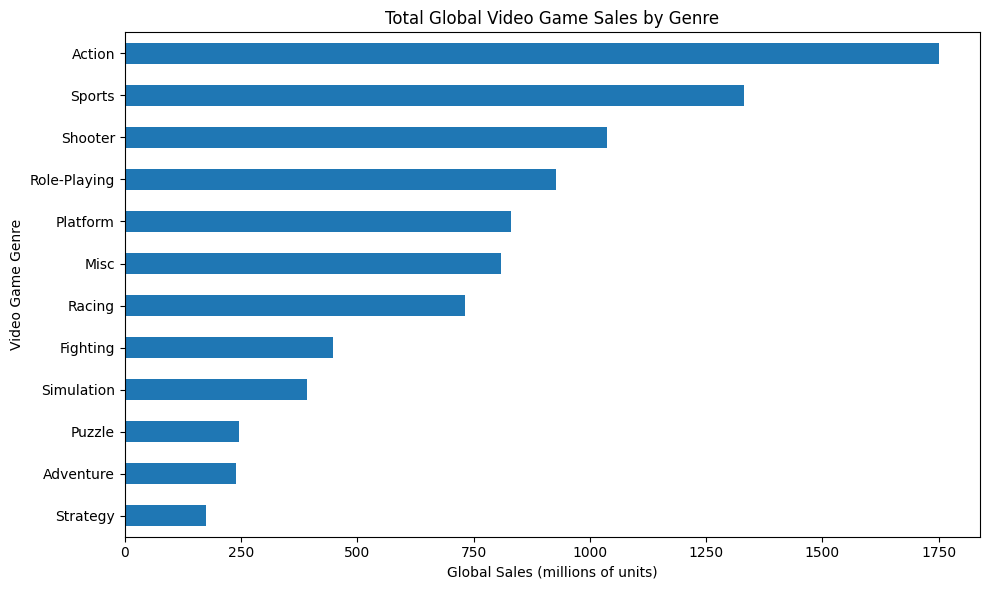

In [ ]:

import matplotlib.pyplot as plt

# Calculate total global sales for each genre
genre_sales = (
    df.dropna(subset=["Genre", "Global_Sales"])
      .groupby("Genre")["Global_Sales"]
      .sum()
      .sort_values(ascending=True)
)

# Create the bar chart
plt.figure(figsize=(10, 6))
genre_sales.plot(kind="barh")

plt.title("Total Global Video Game Sales by Genre")
plt.xlabel("Global Sales (millions of units)")
plt.ylabel("Video Game Genre")
plt.tight_layout()
plt.show()


Figure 1. Total Global Video Game Sales by Genre. This bar chart compares total recorded global sales across video game genres. Action, Sports, and Shooter are among the highest-selling genres in the dataset. The chart highlights differences in cumulative sales across genres, but it does not show average sales per game.

In [ ]:

# Remove records without a release year
df_year = df.dropna(subset=["Year", "Global_Sales"]).copy()

# Convert year values to integers
df_year["Year"] = df_year["Year"].astype(int)

# Calculate total global sales by release year
year_sales = (
    df_year.groupby("Year")["Global_Sales"]
           .sum()
           .sort_index()
)

display(year_sales.reset_index(name="Total Global Sales (millions)").head(10))


,Year,Total Global Sales (millions)
0,1980,11.38
1,1981,35.77
2,1982,28.86
3,1983,16.79
4,1984,50.36
5,1985,53.94
6,1986,37.07
7,1987,21.74
8,1988,47.22
9,1989,73.45


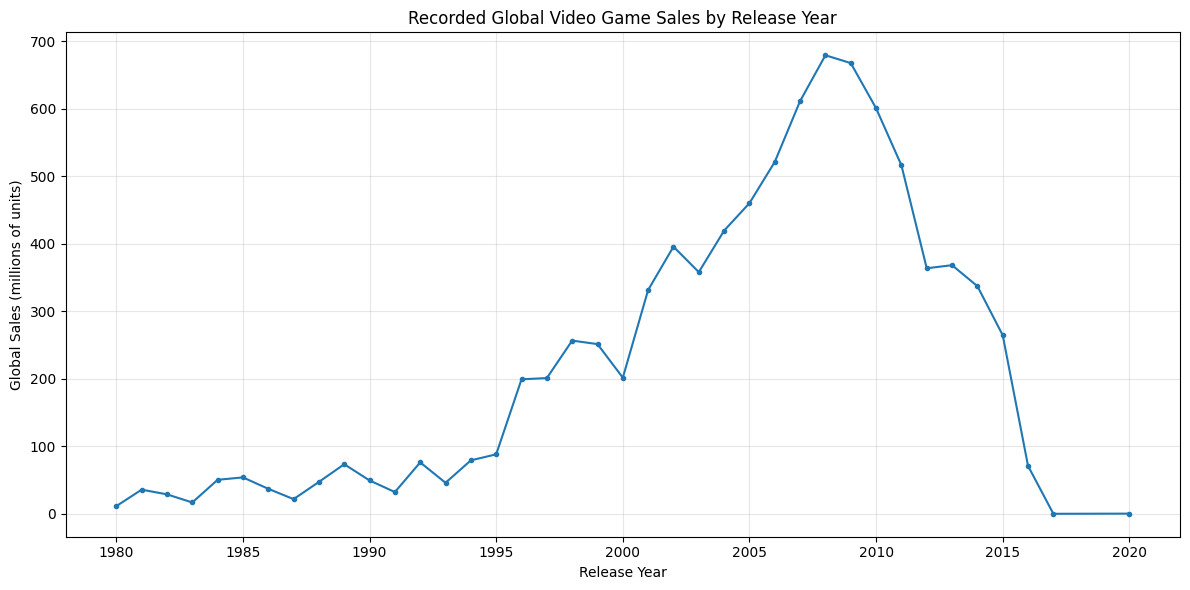

In [ ]:

import matplotlib.pyplot as plt

# Create a line chart of global sales by year
plt.figure(figsize=(12, 6))
plt.plot(year_sales.index, year_sales.values, marker="o", markersize=3)

plt.title("Recorded Global Video Game Sales by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Global Sales (millions of units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Figure 2. Recorded Global Video Game Sales by Release Year. This line chart shows the total recorded global sales of games released in each year. Peaks indicate years with higher summed sales among the games represented in the dataset. The totals should be interpreted cautiously because the dataset may not contain every game released in every year, and some release years are missing.

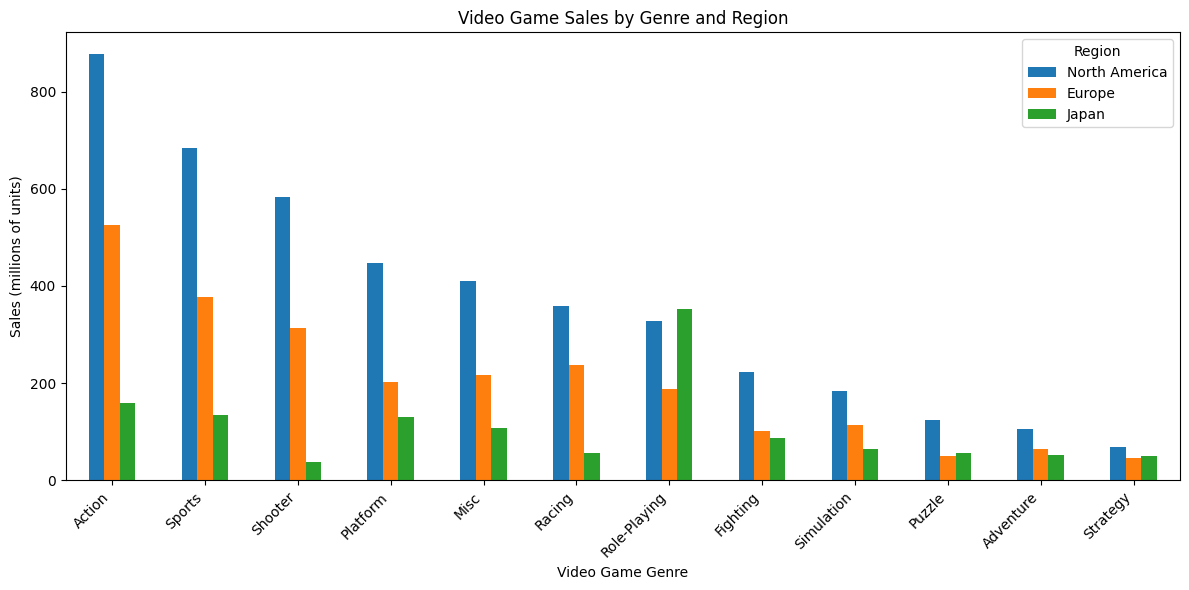

In [ ]:

# Calculate regional sales totals by genre
regional_sales = (
    df.groupby("Genre")[["NA_Sales", "EU_Sales", "JP_Sales"]]
      .sum()
      .sort_values("NA_Sales", ascending=False)
)

# Create a grouped bar chart
regional_sales.plot(kind="bar", figsize=(12, 6))

plt.title("Video Game Sales by Genre and Region")
plt.xlabel("Video Game Genre")
plt.ylabel("Sales (millions of units)")
plt.legend(["North America", "Europe", "Japan"], title="Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Figure 3. Video Game Sales by Genre and Region. This bar chart compares recorded sales in North America, Europe, and Japan across video game genres. Differences in bar heights show how the distribution of sales varies by region. The chart excludes the dataset's “Other” sales category, so the three regional values do not represent all global sales.